# 🐶 DogTranslator — Part 2, data optimisation on CPU (last-layer retraining)

Colab gave us **no GPU**, and retraining ResNet-50, EfficientNet and ViT from start on a CPU would take many hours per model. So for the data optimisation (Acts B and C) we use a technique that is fast on CPU and well known in research: **last-layer retraining**.

**The idea, in 3 steps:**
1. Keep each network **already trained on GPU** in Act A (the BEFORE models).
2. Pass every photo through it **once** and keep the numbers it produces just before its final decision (its *features*). This is prediction only, no training.
3. Retrain **only the last layer**, the part that turns features into an emotion, on the **optimised data** (wrong labels removed, extra augmented photos, mirror trick at test time).

Research on "last-layer retraining" showed that most of what a network learns about a dataset problem (imbalance, wrong labels, shortcuts) can be corrected in this final layer alone, without retraining the whole network.

**What this notebook does:**

| Step | What | Time on CPU |
|---|---|---|
| B1 | Find wrong labels (fixed, careful version) | ~2 min |
| Features | Extract features once from the 4 BEFORE networks (cached in Drive) | ~1h30–2h total |
| B5 | Ablation: which data change helps? (on ResNet-50, decided on **validation**) | ~3 min |
| C | AFTER: all 10 models with the optimised data | ~15 min |

💾 **Resumable:** every feature file and result is saved to Drive at once. If Colab disconnects, run everything again: finished parts are loaded, not recomputed.

**Then** open the **RESUME notebook (from Act D)** to get all the before/after comparisons, Grad-CAM, error analysis and the demo.

In [1]:
!pip install -q timm scikit-image

In [2]:
import os, re, time, json, random, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import torch, torch.nn as nn
from torchvision import transforms
import timm
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict, StratifiedKFold
warnings.filterwarnings("ignore")

# ▶▶ SAME PATHS AS THE MAIN NOTEBOOK ◀◀
REPO_URL = "https://github.com/farahbenchoug13/mlproject.git"
REPO = Path(os.environ.get("DOG_REPO", "/content/mlproject"))
CLEAN_DIR = Path(os.environ.get("DOG_CLEAN_DIR", str(REPO / "data")))
OUT = Path(os.environ.get("DOG_OUT", "/content/drive/MyDrive/dogs part 2 jamila/final_clean"))

# ▶▶ CPU BUDGET (lower these numbers if you are short on time) ◀◀
AUG_COPIES = {"TinyCNN (from scratch)": None, "EfficientNet-B0 fine-tuned": None,   # None = one augmented copy of every training photo
              "ResNet50 fine-tuned": 4000, "ViT fine-tuned": 1500}                  # number of augmented copies for the slow models
VIT_TRAIN_N = 3000                                                                   # ViT is very slow on CPU: use 3,000 training photos for its last layer

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABELS = ["angry", "happy", "relaxed", "sad"]; L2I = {l: i for i, l in enumerate(LABELS)}
COLORS = {"angry": "#E4572E", "happy": "#F3A712", "relaxed": "#4CB944", "sad": "#2E86AB"}; PALETTE = [COLORS[l] for l in LABELS]
TEST = os.environ.get("DOG_TEST") == "1"
VIT_NAME = "vit_tiny_patch16_224" if TEST else "vit_base_patch16_224"
BS = 8 if TEST else 32
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "font.size": 10})
print("Device:", DEVICE, "| CPU threads:", torch.get_num_threads())

Device: cpu | CPU threads: 2


In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive"); WORK = Path("/content")
except ImportError:
    WORK = Path(".")
FIG_DIR, TAB_DIR, MODEL_DIR, PROB_DIR, HIST_DIR, FEAT_DIR = (OUT / d for d in ["figures", "tables", "models", "probs", "histories", "cpu_features"])
for d in [FIG_DIR, TAB_DIR, FEAT_DIR]: d.mkdir(parents=True, exist_ok=True)
assert (OUT / "all_results.csv").exists(), f"No saved results in {OUT}: run Act A of the main notebook first"

def _slug(t, d="item"):
    s = re.sub(r"[^a-zA-Z0-9]+", "_", t or "").strip("_").lower()[:70]
    return s or d
if not getattr(plt.show, "_autosave", False):
    _orig_show = plt.show
    def _show_and_save(*a, **k):
        fig = plt.gcf()
        if fig.axes:
            title = fig._suptitle.get_text() if fig._suptitle else next((ax.get_title() for ax in fig.axes if ax.get_title()), "")
            path = FIG_DIR / f"{len(list(FIG_DIR.glob('*.png'))) + 1:03d}_{_slug(title, 'figure')}.png"
            fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white"); print("💾", path.name)
        return _orig_show(*a, **k)
    _show_and_save._autosave = True; plt.show = _show_and_save

if not (CLEAN_DIR / "splits.csv").exists():
    !git clone -q --depth 1 {REPO_URL} {REPO}
print("Results folder:", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Results folder: /content/drive/MyDrive/dogs part 2 jamila/final_clean


In [4]:
# ---- Same data table and split as the main notebook ----
sp = pd.read_csv(CLEAN_DIR / "splits.csv").rename(columns={"filepath": "path"})
sp["label"] = sp.label.str.lower()
def resolve(p):
    parts = Path(p).parts
    for cand in [Path(p)] + [CLEAN_DIR.joinpath(*parts[i:]) for i in range(len(parts))]:
        if cand.exists(): return str(cand)
    return None
sp["path"] = [resolve(p) for p in tqdm(sp.path, desc="finding files")]
data = sp.dropna(subset=["path"]).reset_index(drop=True)
def _opens(p):
    try:
        with Image.open(p): return True
    except Exception:
        return False
with ThreadPoolExecutor(8) as ex:
    data["ok"] = list(ex.map(_opens, data.path))
data = data[data.ok].reset_index(drop=True)
data["y"] = data.label.map(L2I)

CACHE = WORK / "resized_final"           # small copies (max 288 px) = much faster on CPU
def shrink(args):
    i, p = args
    dst = CACHE / f"{i:05d}.jpg"
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        im = ImageOps.exif_transpose(Image.open(p)).convert("RGB"); im.thumbnail((288, 288)); im.save(dst, quality=92)
    return str(dst)
with ThreadPoolExecutor(8) as ex:
    data["small"] = list(tqdm(ex.map(shrink, zip(data.index, data.path)), total=len(data), desc="resizing"))
PATHS, Y = data.small.values, data.y.values
tr, va, te = (np.where(data.split.values == s)[0] for s in ["train", "val", "test"])
print(f"{len(data)} images | train {len(tr)} | val {len(va)} | test {len(te)}")

finding files:   0%|          | 0/13238 [00:00<?, ?it/s]

resizing:   0%|          | 0/13238 [00:00<?, ?it/s]

13238 images | train 9266 | val 1986 | test 1986


In [5]:
# ---- Results are added to the same file as the main notebook ----
RES_CSV = OUT / "all_results.csv"
RESULTS = pd.read_csv(RES_CSV).to_dict("records")
def _key(name): return _slug(name, "model")
def record(name, family, stage, probs, train_time, n_params=None, val_f1=np.nan, extra=None):
    global RESULTS
    yt, yp = Y[te], probs.argmax(1)
    per = f1_score(yt, yp, average=None, labels=range(4))
    row = dict(model=name, base=name.rsplit(" [", 1)[0], family=family, stage=stage, accuracy=accuracy_score(yt, yp),
               macro_f1=f1_score(yt, yp, average="macro"), val_macro_f1=val_f1, train_time_s=train_time, params=n_params,
               **{f"f1_{l}": v for l, v in zip(LABELS, per)}, **(extra or {}))
    RESULTS = [r for r in RESULTS if r["model"] != name] + [row]
    pd.DataFrame(RESULTS).to_csv(RES_CSV, index=False); np.save(PROB_DIR / f"{_key(name)}.npy", probs)
    print(f"✅ {name:46s} test macro F1 {row['macro_f1']:.3f} | angry F1 {per[0]:.2f} | val F1 {val_f1:.3f}")
before = pd.DataFrame(RESULTS).query("stage == 'before'")
print("BEFORE results found:", len(before), "models")
display(before[["base", "macro_f1", "f1_angry"]].sort_values("macro_f1", ascending=False).round(3)) if "display" in dir() else print(before[["base", "macro_f1"]])

BEFORE results found: 10 models
                          base  macro_f1
0       TinyCNN (from scratch)  0.377465
1          ResNet50 fine-tuned  0.557741
2   EfficientNet-B0 fine-tuned  0.503400
3               ViT fine-tuned  0.566917
15        Dummy (lazy guesser)  0.119102
16              k-NN on pixels  0.274868
17            LogReg on pixels  0.280495
18     Random forest on colors  0.306697
19           Linear SVM on HOG  0.303578
20    ResNet50 frozen + LogReg  0.414030


## B1. Finding wrong labels (careful version) 🔎
Our first label checker was **overconfident**: its answers piled up at 0% and 100%, so it flagged far too many photos and would have removed a quarter of the angry dogs. This version uses a **more careful judge** (stronger regularisation) and removes **at most 5% of any single emotion**.

The judge works on the frozen ImageNet ResNet-50 features already computed in Act A, so this is fast on CPU.

Suspicious training labels: 461 of 9266 (5.0%)
💾 148_label_check_with_a_careful_judge_fixed_version.png


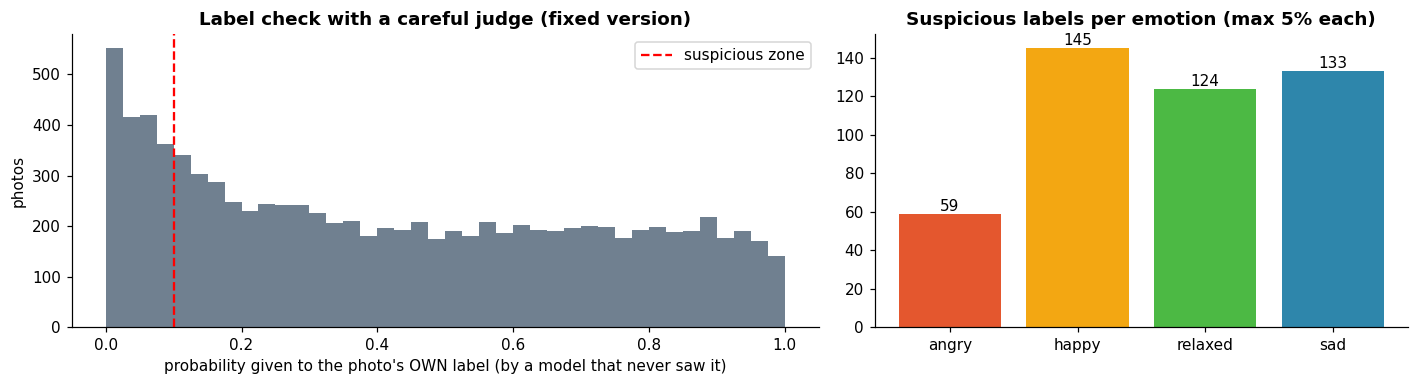

💾 149_most_suspicious_training_labels_careful_version_would_you_agree_with_t.png


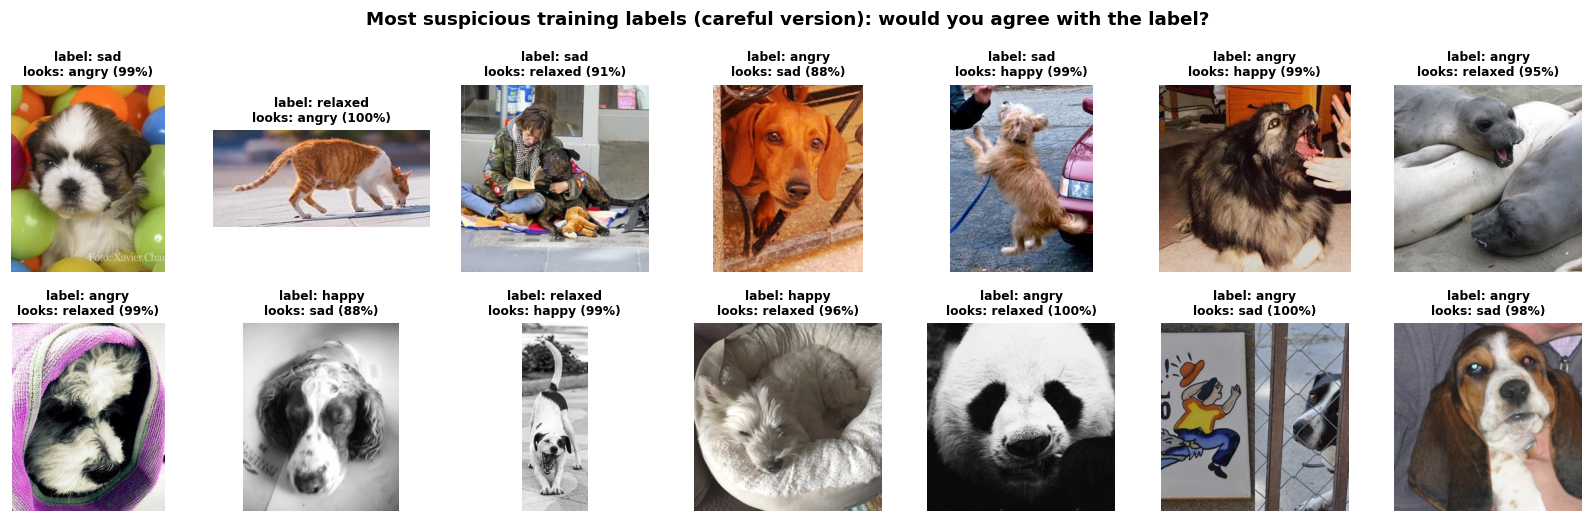

In [6]:
z = np.load(OUT / "resnet50_features.npz"); F_tr, F_va, F_te = z["tr"], z["va"], z["te"]
assert len(F_tr) == len(tr), "Feature file does not match the data: rerun Act A of the main notebook"
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.005, class_weight="balanced"))
oof = cross_val_predict(clf, F_tr, Y[tr], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
p_given = oof[np.arange(len(tr)), Y[tr]]
other = oof.copy(); other[np.arange(len(tr)), Y[tr]] = 0
suspicious = (p_given < 0.10) & (other.max(1) > 0.60)
for c in range(4):                                # never remove more than 5% of ANY emotion (protects angry)
    in_c = np.where(Y[tr] == c)[0]; cap_c = int(0.05 * len(in_c)); flagged = in_c[suspicious[in_c]]
    if len(flagged) > cap_c:
        keep_flag = flagged[np.argsort(p_given[flagged])[:cap_c]]; suspicious[flagged] = False; suspicious[keep_flag] = True
removed = pd.Series(Y[tr][suspicious]).map(dict(enumerate(LABELS))).value_counts().reindex(LABELS, fill_value=0)
print(f"Suspicious training labels: {suspicious.sum()} of {len(tr)} ({suspicious.mean():.1%})")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax[0].hist(p_given, bins=40, color="slategray"); ax[0].axvline(0.10, color="red", ls="--", label="suspicious zone")
ax[0].set_xlabel("probability given to the photo's OWN label (by a model that never saw it)"); ax[0].set_ylabel("photos")
ax[0].set_title("Label check with a careful judge (fixed version)"); ax[0].legend()
b = ax[1].bar(LABELS, removed, color=PALETTE); ax[1].bar_label(b); ax[1].set_title("Suspicious labels per emotion (max 5% each)")
plt.tight_layout(); plt.show()
k = np.where(suspicious)[0][np.argsort(p_given[suspicious])][:14]
if len(k):
    fig, axes = plt.subplots(int(np.ceil(len(k) / 7)), 7, figsize=(15, 2.4 * int(np.ceil(len(k) / 7))), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for a, j in zip(axes.ravel(), k):
        a.imshow(Image.open(PATHS[tr[j]]).convert("RGB")); a.set_title(f"label: {LABELS[Y[tr[j]]]}\nlooks: {LABELS[oof[j].argmax()]} ({oof[j].max():.0%})", fontsize=8)
    plt.suptitle("Most suspicious training labels (careful version): would you agree with the label?", fontweight="bold"); plt.tight_layout(); plt.show()
pd.DataFrame(dict(path=data.path.values[tr][suspicious], label=[LABELS[i] for i in Y[tr][suspicious]],
                  looks_like=[LABELS[i] for i in oof[suspicious].argmax(1)], p_label=p_given[suspicious].round(3))
             ).sort_values("p_label").to_csv(TAB_DIR / "suspicious_training_labels.csv", index=False)

## Extracting features from the 4 trained networks (the slow part) ⏳
For each BEFORE network we compute, once, the numbers it produces just before its final layer:
- **train** photos (normal),
- **train, augmented**: one extra *strongly augmented* copy of training photos (rotations, contrast, hidden patches). This is how strong augmentation works without retraining the network,
- **val** and **test**, plus their **mirrored** versions (for test-time augmentation).

Everything is saved in Drive (`cpu_features/`) as soon as it's computed. If Colab disconnects, rerun and finished files are reloaded.

> ⏱️ Rough CPU times: TinyCNN ~5 min, EfficientNet ~10–15 min, ResNet-50 ~40–60 min, ViT ~40–60 min. Keep the tab open.

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
def make_tf(size, kind="eval"):
    norm = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    if kind == "eval":
        return transforms.Compose([transforms.Resize((size, size))] + norm)
    return transforms.Compose([transforms.RandomResizedCrop(size, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip(),
                               transforms.TrivialAugmentWide()] + norm + [transforms.RandomErasing(p=0.25, scale=(0.02, 0.15))])

class TinyCNN(nn.Module):
    def __init__(self, n=4):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(self, x): return self.head(self.features(x))

DEEP = {"TinyCNN (from scratch)": (lambda: TinyCNN(), 128),
        "ResNet50 fine-tuned": (lambda: timm.create_model("resnet50", pretrained=False, num_classes=4), 224),
        "EfficientNet-B0 fine-tuned": (lambda: timm.create_model("efficientnet_b0", pretrained=False, num_classes=4), 224),
        "ViT fine-tuned": (lambda: timm.create_model(VIT_NAME, pretrained=False, num_classes=4), 224)}

def load_before(base):
    mk, size = DEEP[base]; m = mk(); m.load_state_dict(torch.load(MODEL_DIR / f"{_key(base + ' [before]')}.pt", map_location="cpu"))
    return m.to(DEVICE).eval(), size
def last_layer(m): return m.head[-1] if isinstance(m, TinyCNN) else m.get_classifier()
@torch.no_grad()
def penultimate(m, x):
    if isinstance(m, TinyCNN): return m.head[:-1](m.features(x))
    return m.forward_head(m.forward_features(x), pre_logits=True)

def _load(p, tf, seed):
    if seed is not None: torch.manual_seed(seed); random.seed(seed)
    return tf(Image.open(p).convert("RGB"))
@torch.no_grad()
def extract(m, size, idx, kind="eval", flip=False, desc=""):
    tf = make_tf(size, kind); out = []
    for s in tqdm(range(0, len(idx), BS), desc=desc, leave=False):
        chunk = idx[s:s + BS]
        x = torch.stack([_load(PATHS[j], tf, SEED + int(j) if kind != "eval" else None) for j in chunk]).to(DEVICE)
        if flip: x = torch.flip(x, dims=[3])
        out.append(penultimate(m, x).float().cpu().numpy())
    return np.concatenate(out)

rng = np.random.RandomState(SEED)
def train_positions(base):          # which training photos each model uses (ViT: a stratified subset)
    if base != "ViT fine-tuned" or VIT_TRAIN_N >= len(tr): return np.arange(len(tr))
    pos = []
    for c in range(4):
        in_c = np.where(Y[tr] == c)[0]; pos += list(np.random.RandomState(SEED + c).choice(in_c, max(1, int(round(VIT_TRAIN_N * len(in_c) / len(tr)))), replace=False))
    return np.sort(np.array(pos))
def aug_positions(base, pos):
    n = AUG_COPIES[base]
    return pos if n is None or n >= len(pos) else np.sort(np.random.RandomState(SEED + 7).choice(pos, n, replace=False))

def features(base, sets):
    feats, m = {}, None
    pos = train_positions(base); apos = aug_positions(base, pos)
    plan = {"train": (tr[pos], "eval", False), "train_aug": (tr[apos], "strong", False), "val": (va, "eval", False),
            "val_flip": (va, "eval", True), "test": (te, "eval", False), "test_flip": (te, "eval", True)}
    for sname in sets:
        f = FEAT_DIR / f"{_key(base)}_{sname}.npy"
        if f.exists():
            feats[sname] = np.load(f); continue
        if m is None: m, size = load_before(base)
        idx, kind, flip = plan[sname]
        t = time.time(); feats[sname] = extract(m, size, idx, kind, flip, desc=f"{base}: {sname}"); np.save(f, feats[sname])
        print(f"  {base}: {sname} {feats[sname].shape} in {(time.time() - t) / 60:.1f} min")
    feats["pos"], feats["apos"] = pos, apos
    return feats

# sanity check: the last layer applied to the features gives exactly the network's own output
m, size = load_before("TinyCNN (from scratch)")
with torch.no_grad():
    x = make_tf(size)(Image.open(PATHS[te[0]]).convert("RGB")).unsqueeze(0).to(DEVICE)
    assert torch.allclose(m(x), last_layer(m)(penultimate(m, x)), atol=1e-4)
print("Feature extraction ready ✓")

Feature extraction ready ✓


In [8]:
ALL_SETS = ["train", "train_aug", "val", "val_flip", "test", "test_flip"]
t0 = time.time()
FEATS = {"ResNet50 fine-tuned": features("ResNet50 fine-tuned", ALL_SETS)}        # ResNet-50 first: the ablation uses it
print(f"ResNet-50 features ready ({(time.time() - t0) / 60:.1f} min)")

ResNet-50 features ready (0.1 min)


## B5. Which data changes really help? (ablation on ResNet-50) 🧪
We retrain only ResNet-50's last layer several times, changing **one thing at a time**, and keep a change only if it improves the **validation** macro F1 (by ≥ 0.005, or ≥ 0.002 for the mirror trick).
- **plain**: same training photos as before;
- **+ label filtering**: without the suspicious labels;
- **+ strong augmentation**: training photos + strongly augmented copies;
- **+ TTA**: plain, but every validation/test photo is also judged mirrored, and the two answers are averaged.

For each one, the regularisation strength **C** is also chosen on validation (0.01, 0.1 or 1), the way you'd tune any model.

**Balanced sampling:** for a last layer trained with class weights, sampling angry dogs more often has the same effect as giving them more weight, so we keep the class weights and report the **GPU ablation result** for the sampler (it was trained before the GPU was cut).

In [ ]:
def fit_head(X, y, Xva, Xva_flip=None, tta=False):
    best = None
    for C in ([1.0] if TEST else [0.01, 0.1, 1.0]):
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, class_weight="balanced")).fit(X, y)
        pv = clf.predict_proba(Xva)
        if tta: pv = (pv + clf.predict_proba(Xva_flip)) / 2
        f = f1_score(Y[va], pv.argmax(1), average="macro")
        if best is None or f > best[2]: best = (clf, C, f)
    return best

def head_data(Fd, use_filter, use_aug):
    pos = Fd["pos"]; keep = ~suspicious[pos] if use_filter else np.ones(len(pos), bool)
    X, y = Fd["train"][keep], Y[tr[pos]][keep]
    if use_aug:
        akeep = ~suspicious[Fd["apos"]] if use_filter else np.ones(len(Fd["apos"]), bool)
        X = np.concatenate([X, Fd["train_aug"][akeep]]); y = np.concatenate([y, Y[tr[Fd["apos"]]][akeep]])
    return X, y

Fd = FEATS["ResNet50 fine-tuned"]
ABL = {"HEAD plain": dict(f=False, a=False, t=False), "HEAD + label filtering": dict(f=True, a=False, t=False),
       "HEAD + strong augmentation": dict(f=False, a=True, t=False), "HEAD + TTA": dict(f=False, a=False, t=True)}
abl = {}
for name, o in ABL.items():
    t = time.time(); X, y = head_data(Fd, o["f"], o["a"])
    clf, C, vf = fit_head(X, y, Fd["val"], Fd["val_flip"], o["t"])
    pt = clf.predict_proba(Fd["test"]); pt = (pt + clf.predict_proba(Fd["test_flip"])) / 2 if o["t"] else pt
    record(f"{name} [ablation-cpu]", "deep learning", "ablation-cpu", pt, time.time() - t, val_f1=vf,
           extra=dict(train_images=len(y), method="last-layer retraining", C=C))
    abl[name] = vf

r = pd.DataFrame(RESULTS).set_index("model")
gpu_plain, gpu_sampler = "ABL plain [ablation]", "ABL + balanced sampler [ablation]"
sampler_ok = gpu_plain in r.index and gpu_sampler in r.index and r.loc[gpu_sampler, "val_macro_f1"] > r.loc[gpu_plain, "val_macro_f1"] + 0.005
KEEP = dict(filter=abl["HEAD + label filtering"] > abl["HEAD plain"] + 0.005, sampler=bool(sampler_ok),
            strong=abl["HEAD + strong augmentation"] > abl["HEAD plain"] + 0.005, tta=abl["HEAD + TTA"] > abl["HEAD plain"] + 0.002)

o = pd.DataFrame(RESULTS).query("stage == 'ablation-cpu'").set_index("base").loc[list(ABL)]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
kmap = {"HEAD + label filtering": "filter", "HEAD + strong augmentation": "strong", "HEAD + TTA": "tta"}
cols = ["#9e9e9e"] + ["#43A047" if KEEP[kmap[n]] else "#E57373" for n in list(ABL)[1:]]
bars = ax[0].barh(o.index[::-1], (o.val_macro_f1 - abl["HEAD plain"])[::-1], color=cols[::-1]); ax[0].axvline(0, color="k", lw=0.8)
ax[0].axvline(0.005, color="gray", ls=":", label="keep threshold"); ax[0].bar_label(bars, fmt="%+.3f", padding=3, fontsize=8)
ax[0].set_title("Change in VALIDATION macro F1 vs plain (decides)"); ax[0].legend(fontsize=8)
sns.heatmap(o[[f"f1_{l}" for l in LABELS]].rename(columns=lambda c: c[3:]), annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax[1])
ax[1].set_title("Test F1 per emotion (for the report)"); ax[1].set_ylabel("")
plt.suptitle("Ablation (CPU): last-layer retraining of ResNet-50", fontweight="bold"); plt.tight_layout(); plt.show()
if gpu_plain in r.index and gpu_sampler in r.index:
    print(f"Balanced sampler (GPU ablation): val F1 {r.loc[gpu_plain, 'val_macro_f1']:.3f} → {r.loc[gpu_sampler, 'val_macro_f1']:.3f} ⇒ kept: {sampler_ok}")
print("✅ Optimised data recipe:", {k: ("YES" if v else "no") for k, v in KEEP.items()})
json.dump(dict({k: bool(v) for k, v in KEEP.items()}, method="last-layer retraining (CPU)"), open(OUT / "optimised_recipe.json", "w"), indent=2)

# Act C — AFTER: all 10 models with the optimised data 🚀
- **5 classic ML models** and the **frozen ResNet-50**: retrained from scratch (they're fast) without the suspicious labels, if label filtering was kept;
- **4 deep networks**: last layer retrained with the full recipe. The new last layer is put back into the network and saved as the AFTER model, so Grad-CAM and the demo can use it.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from skimage import feature, color as skcolor
mask = ~suspicious if KEEP["filter"] else np.ones(len(tr), bool)

def load_small(p, size=64): return np.asarray(Image.open(p).convert("RGB").resize((size, size)))
with ThreadPoolExecutor(8) as ex:
    X64 = np.stack(list(tqdm(ex.map(load_small, PATHS), total=len(PATHS), desc="loading 64x64")))
X32 = np.stack([np.asarray(Image.fromarray(x).resize((32, 32))) for x in X64]).reshape(len(X64), -1) / 255.0
def color_hist(x):
    q = (x // 64).reshape(-1, 3); h = np.bincount(q[:, 0] * 16 + q[:, 1] * 4 + q[:, 2], minlength=64); return h / h.sum()
XHIST = np.stack([color_hist(x) for x in X64])
XHOG = np.stack([feature.hog(skcolor.rgb2gray(x), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for x in tqdm(X64, desc="HOG")])
classic = [("Dummy (lazy guesser)", DummyClassifier(strategy="most_frequent"), X32),
           ("k-NN on pixels", make_pipeline(StandardScaler(), KNeighborsClassifier(5)), X32),
           ("LogReg on pixels", make_pipeline(StandardScaler(), LogisticRegression(max_iter=300, class_weight="balanced")), X32),
           ("Random forest on colors", RandomForestClassifier(300, class_weight="balanced", n_jobs=-1, random_state=SEED), XHIST),
           ("Linear SVM on HOG", make_pipeline(StandardScaler(), LinearSVC(C=0.01, class_weight="balanced")), XHOG)]
for base, model, X in classic:
    t = time.time(); model.fit(X[tr[mask]], Y[tr[mask]])
    record(f"{base} [after]", "classic ML", "after", np.eye(4)[model.predict(X[te])], time.time() - t, extra=dict(train_images=int(mask.sum())))

t = time.time()
fz = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=0.5, class_weight="balanced")).fit(F_tr[mask], Y[tr][mask])
record("ResNet50 frozen + LogReg [after]", "transfer (frozen)", "after", fz.predict_proba(F_te), time.time() - t,
       val_f1=f1_score(Y[va], fz.predict(F_va), average="macro"), extra=dict(train_images=int(mask.sum())))

loading 64x64:   0%|          | 0/13238 [00:00<?, ?it/s]

HOG:   0%|          | 0/13238 [00:00<?, ?it/s]

✅ Dummy (lazy guesser) [after]                   test macro F1 0.119 | angry F1 0.00 | val F1 nan
✅ k-NN on pixels [after]                         test macro F1 0.275 | angry F1 0.11 | val F1 nan
✅ LogReg on pixels [after]                       test macro F1 0.277 | angry F1 0.17 | val F1 nan
✅ Random forest on colors [after]                test macro F1 0.307 | angry F1 0.04 | val F1 nan
✅ Linear SVM on HOG [after]                      test macro F1 0.304 | angry F1 0.15 | val F1 nan
✅ ResNet50 frozen + LogReg [after]               test macro F1 0.414 | angry F1 0.23 | val F1 0.418


In [ ]:
need = ["train", "val", "test"] + (["train_aug"] if KEEP["strong"] else []) + (["val_flip", "test_flip"] if KEEP["tta"] else [])
for base in ["TinyCNN (from scratch)", "EfficientNet-B0 fine-tuned", "ResNet50 fine-tuned", "ViT fine-tuned"]:
    t0 = time.time()
    Fd = FEATS[base] if base in FEATS else features(base, need)
    X, y = head_data(Fd, KEEP["filter"], KEEP["strong"])
    clf, C, vf = fit_head(X, y, Fd["val"], Fd.get("val_flip"), KEEP["tta"])
    pt = clf.predict_proba(Fd["test"]); pt = (pt + clf.predict_proba(Fd["test_flip"])) / 2 if KEEP["tta"] else pt
    # put the new last layer back into the network and save it as the AFTER model
    sc, lr = clf.named_steps["standardscaler"], clf.named_steps["logisticregression"]
    W = lr.coef_ / sc.scale_; bvec = lr.intercept_ - W @ sc.mean_
    m, size = load_before(base); lin = last_layer(m)
    with torch.no_grad():
        lin.weight.copy_(torch.tensor(W, dtype=lin.weight.dtype)); lin.bias.copy_(torch.tensor(bvec, dtype=lin.bias.dtype))
    torch.save(m.state_dict(), MODEL_DIR / f"{_key(base + ' [after]')}.pt")
    tr_acc = accuracy_score(y, clf.predict(X))
    pd.DataFrame([dict(epoch=1, train_loss=np.nan, train_acc=tr_acc, val_loss=np.nan, val_acc=np.nan, val_f1=vf)]).to_csv(
        HIST_DIR / f"{_key(base + ' [after]')}.csv", index=False)
    record(f"{base} [after]", "deep learning", "after", pt, time.time() - t0, sum(p.numel() for p in m.parameters()), vf,
           extra=dict(train_images=len(y), method="last-layer retraining (CPU)", C=C, tta=KEEP["tta"]))
    FEATS[base] = Fd; del m

In [ ]:
B = pd.DataFrame(RESULTS).query("stage == 'before'").set_index("base"); A = pd.DataFrame(RESULTS).query("stage == 'after'").set_index("base")
cmp = pd.DataFrame({"F1 before": B.macro_f1, "F1 after": A.macro_f1, "angry before": B.f1_angry, "angry after": A.f1_angry}).dropna()
cmp["Δ F1"] = cmp["F1 after"] - cmp["F1 before"]; cmp = cmp.sort_values("F1 after", ascending=False)
cmp.round(3).to_csv(TAB_DIR / "before_vs_after_cpu.csv")
print(cmp.round(3).to_string())
print("\n✅ Done. Now open the RESUME notebook (from Act D) for all comparisons, Grad-CAM, error analysis and the demo.")

## 📝 How to describe this in the report
> *"No GPU was available for the optimisation stage, so we applied **last-layer retraining**: each network trained in Act A was kept fixed, its penultimate-layer features were extracted once on CPU, and only its final classification layer was retrained on the optimised data (filtered labels, strongly augmented copies, test-time mirroring), with the regularisation strength chosen on the validation set. Classic models and the frozen ResNet-50 were fully retrained, as they are fast. This isolates the effect of the **data**, since the feature extractor is identical before and after."*

**Limitation to mention:** with full GPU fine-tuning, the networks could also adapt their *features* to the optimised data, so the gains here are a lower bound. Strong augmentation was also applied to a subset of photos for ResNet-50 and ViT to keep CPU time reasonable.

**If a GPU becomes available later** and you want full fine-tuning instead: delete the four `*_after.pt` files in `models/` and rerun the main notebook.